# 01 · Explore the penalty data

[Guide](../README.md) | [Previous](00_Learning_Roadmap.ipynb) | [Next](02_Baselines_and_Validation.ipynb)

## 1. What problem are we solving?

What is in one penalty record, and what could go wrong with the data?

## 2. Why does it matter?

Missing values, duplicates, unusual measurements, and uneven class counts affect later choices.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Missing / duplicate | A missing cell has no value; a duplicate repeats a record, according to the columns checked. |
| Frequency / scoring rate | How many kicks belong to a category / the fraction of those kicks that scored. |
| Outlier / shift | An unusual observation / a difference between input distributions. |
| Class imbalance | One target answer occurs more often than the other. |

## 4. Intuitive example

Imagine two records with different IDs but exactly the same measurements and answer: checking IDs alone would miss that duplicate. A blank capacity is missing data; a capacity of 140,000 is an unusual value, not a blank. These require different checks.

## 5. Methods to compare

| View | What it checks | Limit |
|---|---|---|
| Counts and duplicate rules | Blanks, repeated records, class proportions | Similar kicks are not necessarily duplicates |
| Category counts and goal rates | Common groups and outcome associations | Small groups give unstable rates |
| Distributions, boxplots, domain rules | Unusual measurements | Unusual does not prove wrong |
| Correlations and PCA | Relationships and multi-input patterns | Neither proves importance or causation |
| Train/test input comparisons | Different input distributions | Cannot reveal unknown test answers |

## 6. What we retained from previous notebooks

**Prior knowledge:** From 00: one row = one penalty, `is_scored` is its known goal/miss answer; data exploration comes before modeling.

**Carry forward:** Do not select imputation, encoding, or the final model during EDA.

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

### What does one row mean?

One row describes one penalty. IDs name it; other columns describe the kick and its context.

In [4]:
display(training_data.head(3))

,id,kicker_id,keeper_id,match_id,jersey_color,referee_strictness,stadium_capacity,temperature,weather_humidity,match_type,minute_taken,home_or_away,current_score_diff,pitch_condition,crowd_behind_goal,player_last5_scored_percent,goalkeeper_last5_saved_percent,strong_foot_usage,weak_foot_usage,is_scored
0,15747,K68C02082,GK817DE5B8,M3C210E92,Black,0.26,59036.0,27.0,51.0,League,38.0,Home,1,Excellent,Home,60,80,0.726,0.318,1
1,18591,K348D1799,GKED219454,M14254DB3,Purple,0.67,66767.0,33.0,88.0,Friendly,31.0,Away,2,Excellent,Home,0,80,0.670,0.427,0
2,3292,KD7A46D52,GKCD653AF1,M6E7E53CA,White,0.83,38915.0,23.0,35.0,Friendly,82.0,Home,-2,Good,Away,80,60,0.413,0.184,1


In [5]:
summary = pd.DataFrame({
    "type": training_data.dtypes.astype(str),
    "missing rows": training_data.isna().sum(),
    "different values": training_data.nunique(),
})
display(summary)
print("Repeated IDs:", training_data["id"].duplicated().sum())
inputs = training_data.drop(columns=["id", "kicker_id", "keeper_id", "match_id"])
print("Repeated observations without IDs:", inputs.duplicated().sum())

,type,missing rows,different values
id,int64,0,16000
kicker_id,object,0,16000
keeper_id,object,0,16000
match_id,object,0,16000
jersey_color,object,525,8
referee_strictness,float64,457,101
stadium_capacity,float64,428,14336
temperature,float64,470,50
weather_humidity,float64,491,100
match_type,object,0,5


Repeated IDs: 0
Repeated observations without IDs: 0


### Duplicate handling
Exact duplicates repeat the same measurements **and answer**. Similar kicks with different
measurements are not duplicates. Compare three removal rules before deleting anything.

In [6]:
observations = training_data.drop(columns=["id", "kicker_id", "keeper_id", "match_id"])
duplicate_options = {
    "Keep all": observations,
    "Keep first copy": observations.drop_duplicates(keep="first"),
    "Keep last copy": observations.drop_duplicates(keep="last"),
    "Remove every repeated group": observations.drop_duplicates(keep=False),
}
rows = []
for name, data in duplicate_options.items():
    rows.append([name, len(data), len(observations) - len(data)])
display(pd.DataFrame(rows, columns=["strategy", "rows kept", "rows removed"]))

,strategy,rows kept,rows removed
0,Keep all,16000,0
1,Keep first copy,16000,0
2,Keep last copy,16000,0
3,Remove every repeated group,16000,0


**Choice: keep all rows.** No exact duplicates were found, so the removal rules change nothing.
If duplicate IDs or conflicting answers appear, investigate their source instead of choosing an arbitrary answer.

**Missing rows:** count empty cells; fill them in [03](03_Missing_Values_and_Scaling.ipynb).
**Different values:** a nearly unique column may be an ID; it is not automatically useful.
**Duplicates:** inspect them; similar real kicks are not necessarily recording errors.

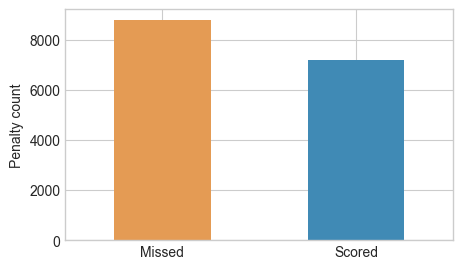

Missed    55.0
Scored    45.0
Name: percent, dtype: float64

In [7]:
counts = training_data["is_scored"].value_counts().sort_index()
counts.index = ["Missed", "Scored"]
counts.plot.bar(rot=0, color=["#e49b54", "#408ab5"], figsize=(5, 3))
plt.ylabel("Penalty count")
plt.show()
display((100 * counts / counts.sum()).round(1).rename("percent"))

### Class balance
**Imbalance** means one answer occurs more often. Here it is mild, about 55% misses
and 45% goals—not a reason to balance automatically. Compare methods in [09](09_Class_Imbalance.ipynb).

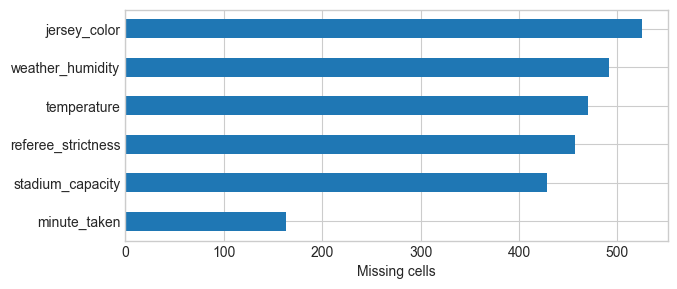

In [8]:
missing = training_data.isna().sum()
missing = missing[missing > 0].sort_values()
missing.plot.barh(figsize=(7, 3))
plt.xlabel("Missing cells")
plt.show()

### How often does a category occur, and how often does it score?
**Frequency** is the number of kicks. **Scoring rate** is the fraction that scored.
A tiny category can have an unreliable rate. These plots suggest features; they do not prove a cause.

,kicks,scoring rate
match_type,,
Cup,3949,0.405
Final,1985,0.504
Friendly,1498,0.475
League,7495,0.444
Playoff,1073,0.527


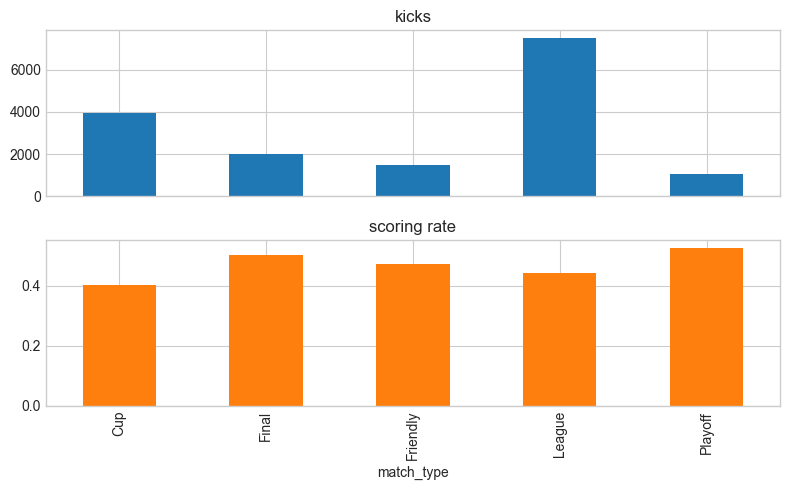

In [9]:
category_summary = training_data.groupby("match_type")["is_scored"].agg(["size", "mean"])
category_summary.columns = ["kicks", "scoring rate"]
display(category_summary.round(3))
category_summary.plot.bar(subplots=True, figsize=(8, 5), legend=False)
plt.tight_layout()
plt.show()

Example: match type and late timing may describe pressure. Test that idea in
[05](05_Feature_Engineering.ipynb). Do not put a full-data scoring rate into model
inputs: it would use answers from validation rows (**data leakage**).

### Relationships and possible distractions
**Correlation** measures a straight-line relationship: +1 rises together, −1 moves oppositely, 0 has no linear trend.
It does not prove causation. Near-zero correlation does not rule out useful curves or combinations.
This picture suggests questions for feature engineering (05) and selection (06); it does not choose columns.

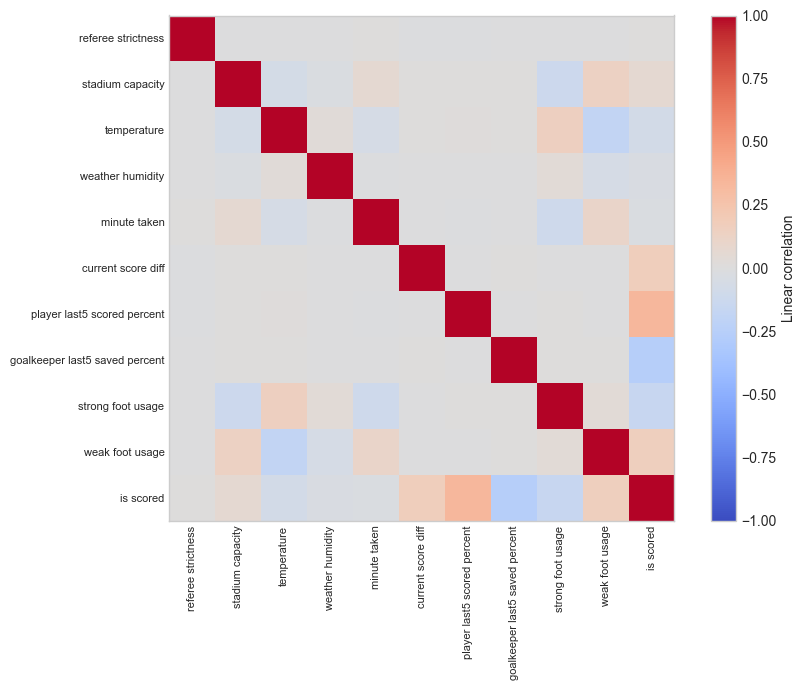

goalkeeper_last5_saved_percent   -2.611e-01
strong_foot_usage                -1.520e-01
temperature                      -7.686e-02
weather_humidity                 -3.158e-02
minute_taken                     -2.975e-02
referee_strictness                6.538e-04
stadium_capacity                  5.836e-02
weak_foot_usage                   1.618e-01
current_score_diff                1.701e-01
player_last5_scored_percent       3.324e-01
Name: correlation with goals, dtype: float64

In [10]:
numeric = training_data.drop(columns=["id"]).select_dtypes(include="number")
correlation = numeric.corr()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.grid(False)
names = correlation.columns.str.replace("_", " ")
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
fig.colorbar(image, ax=ax, label="Linear correlation")
plt.tight_layout()
plt.show()
display(correlation["is_scored"].drop("is_scored").sort_values().rename("correlation with goals"))

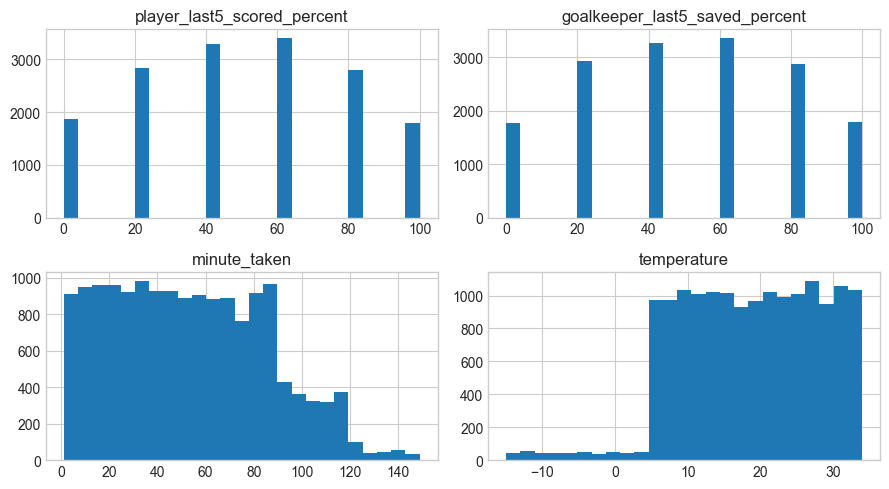

In [11]:
columns = ["player_last5_scored_percent", "goalkeeper_last5_saved_percent", "minute_taken", "temperature"]
training_data[columns].hist(bins=25, figsize=(9, 5))
plt.tight_layout()
plt.show()

### Boxplots: another outlier screen
The box is the middle half of observations. Dots beyond the whiskers are unusual values,
not automatically errors. Compare this column-by-column view with the PCA picture below.

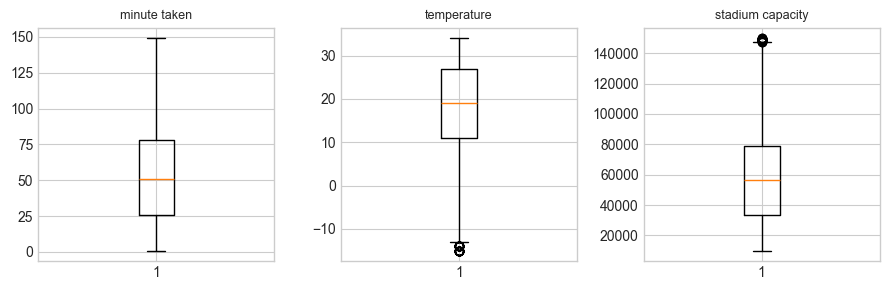

In [12]:
columns = ["minute_taken", "temperature", "stadium_capacity"]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for axis, column in zip(axes, columns):
    axis.boxplot(training_data[column].dropna())
    axis.set_title(column.replace("_", " "), fontsize=9)
plt.tight_layout()
plt.show()

### See unusual rows with PCA
**PCA** compresses many numerical columns into two coordinates.
Nearby points have similar scaled measurements. Isolated points deserve inspection,
not automatic deletion. The axes are mixtures of features, not football measurements.

In [13]:
from sklearn.decomposition import PCA
numeric = training_data.drop(columns=["id", "is_scored"]).select_dtypes(include="number")
filled = SimpleImputer(strategy="median").fit_transform(numeric)
scaled = StandardScaler().fit_transform(filled)
coordinates = PCA(n_components=2).fit_transform(scaled)

In [14]:
def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

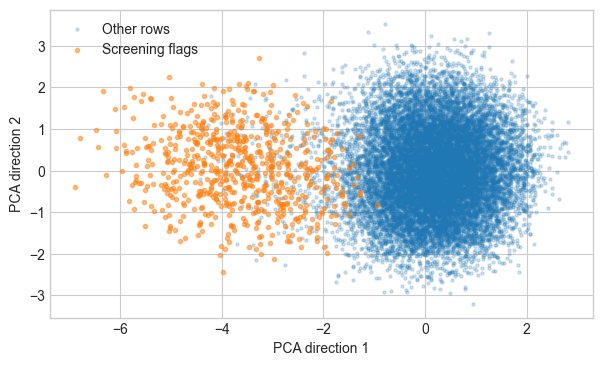

,id,minute_taken,temperature,stadium_capacity
5,8440,132.0,26.0,115257.0
86,15921,34.0,NaN,113098.0
116,12164,19.0,0.0,132328.0
144,10209,20.0,14.0,118533.0
146,15015,41.0,5.0,142069.0


In [15]:
flagged = suspicious_rows(training_data)
plt.figure(figsize=(7, 4))
plt.scatter(coordinates[~flagged, 0], coordinates[~flagged, 1], s=5, alpha=0.2, label="Other rows")
plt.scatter(coordinates[flagged, 0], coordinates[flagged, 1], s=9, alpha=0.5, label="Screening flags")
plt.xlabel("PCA direction 1")
plt.ylabel("PCA direction 2")
plt.legend()
plt.show()
display(training_data.loc[flagged, ["id", "minute_taken", "temperature", "stadium_capacity"]].head())

The screen flags minute > 120, temperature < 0°C, or capacity > 110,000.
These can be real events; check their source before calling them errors.
[08](08_Outlier_Handling.ipynb) tests removing flagged **training** rows while keeping evaluation rows.

### Distribution shift: are the inputs different?
**Shift** means a column occurs differently in train and test.
Compare relative frequencies using the same bins. **Density** rescales each histogram
to area 1, so different sample sizes are comparable. Different bar heights show a change;
they do not reveal the test answers or prove the model will fail.

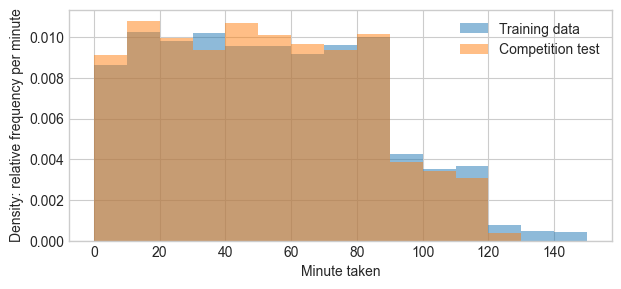

In [16]:
bins = np.arange(0, 160, 10)
plt.figure(figsize=(7, 3))
plt.hist(training_data["minute_taken"], bins=bins, density=True, alpha=0.5, label="Training data")
plt.hist(test["minute_taken"], bins=bins, density=True, alpha=0.5, label="Competition test")
plt.xlabel("Minute taken")
plt.ylabel("Density: relative frequency per minute")
plt.legend()
plt.show()

### Shift example: compare percentages, not row counts
A change from 10% to 15% is **5 percentage points**, even when the files have different row counts.
Text categories can shift too. The example below compares match types without using test answers.

,training %,test %,change in percentage points
match_type,,,
League,46.84,50.65,3.81
Cup,24.68,24.42,-0.26
Final,12.41,10.08,-2.32
Friendly,9.36,9.73,0.37
Playoff,6.71,5.12,-1.59


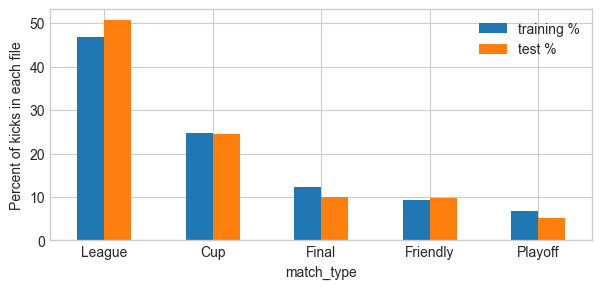

Largest match-type change: League
Percentage points: 3.81


In [17]:
proportions = pd.DataFrame({
    "training %": 100 * training_data["match_type"].value_counts(normalize=True),
    "test %": 100 * test["match_type"].value_counts(normalize=True),
}).fillna(0)
proportions["change in percentage points"] = proportions["test %"] - proportions["training %"]
display(proportions.round(2))
proportions[["training %", "test %"]].plot.bar(rot=0, figsize=(7, 3))
plt.ylabel("Percent of kicks in each file")
plt.show()
biggest = proportions["change in percentage points"].abs().idxmax()
print("Largest match-type change:", biggest)
print("Percentage points:", round(proportions.loc[biggest, "change in percentage points"], 2))

**Decision:** keep these inputs. A distribution difference is a warning, not a reason to delete a feature
or change class counts automatically. Check performance by subgroup in 14; test outcomes remain unknown.

### What happens next?
| Finding | Action |
|---|---|
| Missing cells | Compare filling methods in 03 |
| Text categories | Encode in 04 |
| Pressure/form ideas | Test features in 05 |
| Weak or distracting inputs | Check importance in 06 |
| Isolated PCA points | Compare keeping/removing in 08 |
| Unequal class counts | Compare balancing in 09 |
| Train/test differences | Expect validation and leaderboard scores to differ |

**Leakage:** the model receives information unavailable at prediction time.
**Overfitting:** it learns patterns that work on training rows but fail on new rows.
Leakage can make validation look falsely good; overfitting can happen even without leakage.

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Inspect tables, class counts, category frequencies/rates, distributions, boxplots, PCA, and train/test input differences. |
| Which performed best? | Not applicable: EDA identifies issues; it does not select a model using F1. |
| Why did we choose it? | First inspect what is missing or unusual; defer interventions to controlled comparisons. |
| What are its limitations? | Plots flag questions, not causal effects or confirmed errors. Unlabeled inputs cannot reveal the true test goal fraction. |
| What continues to the next notebook? | Keep rows (no exact duplicates found); investigate missing values, candidate distractions, unusual rows, and mild class imbalance in their lessons. |

## 10. Key takeaways and next step

- A suspicious value is a question to investigate, not automatic proof of an error.
- Separate IDs, inputs, and the answer before modeling.

Next: [02 Baselines and Validation](02_Baselines_and_Validation.ipynb).